# 計算機数学 II 期末レポート

[student number removed]
カウエ　シンゴ　アラマキ

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [75]:
def err_plot(rows, title, labels=["label1", "label2", "label3"]): # 誤差表の表示
    fig, ax = plt.subplots()     # 図と軸を作成
    ax.axis('off')               # 軸を非表示にする

    table = ax.table(            # 表オブジェクトを作成
        cellText=rows,
        colLabels=labels,
        loc="center"
    )
    plt.title(title)  # タイトルを設定
    plt.show()        # 表を表示

def err_ratios(rows, Ns): # 誤差をの比の計算と表示
    err = [abs(float(r[2])) for r in rows]
    
    ratio_rows = [] 
    for i in range(len(err)-1): # 誤差の比と収束次数を計算
        r = err[i] / err[i+1]
        p = np.log2(r) # 収束次数の計算
        ratio_rows.append([f"{Ns[i]} to {Ns[i+1]}", f"{r:.2f}", f"{p:.2f}"])

    # Matplotlib表
    fig, ax = plt.subplots()
    ax.axis('off')

    table = ax.table(
        cellText=ratio_rows,
        colLabels=["N to N+1", "ratio", "p"],
        loc="center"
    )
    plt.title("error ratios")
    plt.show()                    # 表を表示

## 問1 複合2点Gauss求積公式

In [76]:
# func定義
def gauss_2pt(f, a: float, b: float, N: int) -> float: # 複合2点Gauss型数値積分公式を実装する関数
    h = (b - a) / N                      # 区間 [a,b] を N 等分したときの刻み幅 h を計算
    inv_sqrt3 = 1.0 / np.sqrt(3.0)       # Gauss2点公式で用いる 1/√3 をあらかじめ計算
    total = 0.0                          # 積分値の総和を初期化

    for i in range(N):  # 各小区間ごとにGauss2点公式を適用するループ
        ai = a + i * h                      # i番目の小区間の左端 ai と右端 bi を計算
        bi = ai + h
        m = 0.5 * (ai + bi)                 # 小区間の中点 m を計算
        half = 0.5 * (bi - ai)              # 区間長の半分（= h/2）を計算

        x1 = m - half * inv_sqrt3           # Gauss2点公式の評価点（中点 ± half/√3）
        x2 = m + half * inv_sqrt3

        total += half * (f(x1) + f(x2))     # この小区間での近似積分値を加算

    return total    # 全小区間の和を返す（これが積分近似値 Q_N）

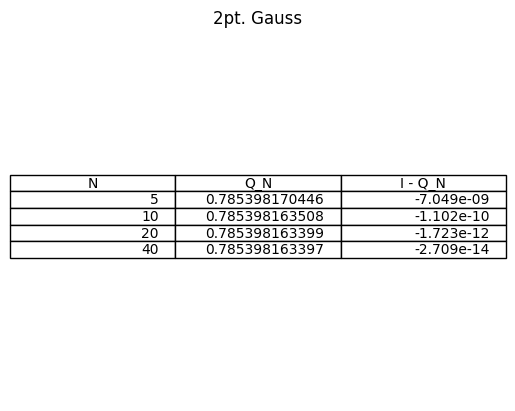

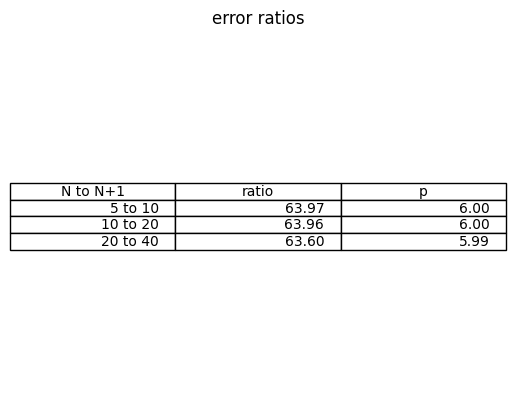

In [80]:
# パラメータ設定
def f_1(x: float) -> float: # 被積分関数 f(x) = 1/(x^2+1) を定義する
    return 1.0 / (x**2 + 1.0)

a, b = 0.0, 1.0  # 積分区間 [a,b] を設定
I_exact = np.pi / 4.0                      # 厳密値 I = π/4
Ns = [5, 10, 20, 40]                       # 分割数 N のリスト

rows1 = []
for N in Ns:                                # 各 N について数値積分と誤差を計算
    QN = gauss_2pt(f_1, a, b, N)                    # 複合Gauss2点公式による近似値 Q_N を計算
    err = I_exact - QN                            # 誤差（厳密値 − 近似値）を計算
    rows1.append([N, f"{QN:.12f}", f"{err:.3e}"])  # 表用に整形して保存
# Matplotlib表
err_plot(rows1, "2pt. Gauss", labels=["N", "Q_N", "I - Q_N"])
err_ratios(rows1, Ns)

$$
I=\int_0^1 \frac{1}{1+x^2}\,dx=\frac{\pi}{4}
$$
を，複合2点Gauss求積公式によって数値的に計算した。

分割数を  $N=5,10,20,40$ と増やしたときの近似値 $Q_N$ と誤差 $I-Q_N$ を比較すると，$N$ の増加に伴って誤差の絶対値が急速に減少していることが分かる。

区間幅を $h=1/N$ とすると，複合2点Gauss公式の大域誤差は一般に

$$
I - Q_N = O(h^4)
$$

となることが知られている。したがって，$N$ を2倍（$h$ を1/2）にすると，誤差は理論上およそ $2^4=16$ 分の1になることが期待される。

実際の計算結果から誤差の比
$$
\frac{|I-Q_N|}{|I-Q_{2N}|}
$$
を取ると，いずれも約64倍となっている。これは理論値16よりもさらに速い収束を示している。被積分関数
$$
f(x)=\frac{1}{1+x^2}
$$
は区間 $[0,1]$ 上で非常に滑らかであり，高次導関数も有界で小さいため，誤差展開の先頭係数が小さくなり，より高次の項が支配的になった結果と考えられる。このため，実験的には4次より高い次数で収束しているように観測される。

また，$N=40$ の場合には誤差が $10^{-14}$ 程度まで減少しており，これは倍精度浮動小数点の丸め誤差の影響が無視できなくなる領域である。したがって，これ以上分割数を増やしても，打ち切り誤差よりも丸め誤差が支配的となり，改善は限定的になると考えられる。


## 問2 Runge–Kutta 法 RK4

In [73]:
# func定義
def rk4_1over6_step(f, t: float, u: float, h: float) -> float: # 4次Runge–Kutta法（1/6公式）で1ステップ進める
    k1 = f(t, u)                              # k1 = f(t_n, u_n)
    k2 = f(t + 0.5*h, u + 0.5*h*k1)           # k2 = f(t_n+h/2, u_n + h*k1/2)
    k3 = f(t + 0.5*h, u + 0.5*h*k2)           # k3 = f(t_n+h/2, u_n + h*k2/2)
    k4 = f(t + h,     u + h*k3)               # k4 = f(t_n+h,   u_n + h*k3)
    return u + (h/6.0)*(k1 + 2*k2 + 2*k3 + k4) # u_{n+1} = u_n + h/6*(k1+2k2+2k3+k4)

def solve_rk4(f, u0: float, t0: float, t_end: float, N: int) -> float: # 区間 [t0,t_end] を N 分割してRK4で解く
    h = (t_end - t0) / N                      # 刻み幅 h を設定
    t, u = t0, u0                             # 時刻 t と解 u を初期化
    for _ in range(N):                        # N ステップ分だけ時間発展させる
        u = rk4_1over6_step(f, t, u, h)        # 1ステップ進める
        t += h                                # 時刻を更新する

    return u                                  # 最終時刻 t_end に対応する数値解 U_N を返す

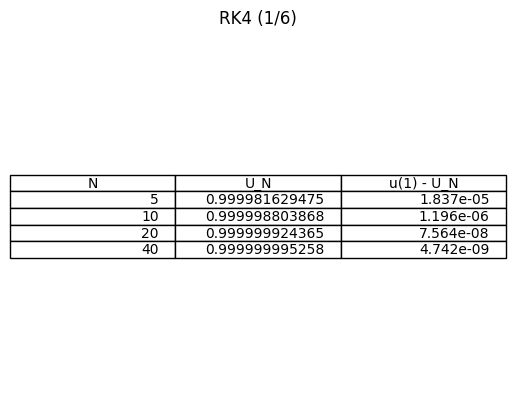

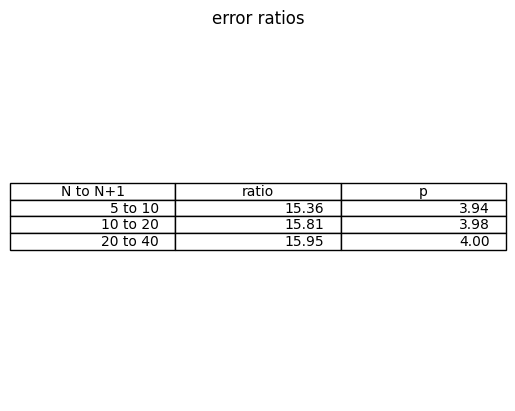

In [79]:
# パラメーター設定
def f_2(t: float, u: float) -> float: # 微分方程式 u'(t) = f(t,u) を定義する（ここでは u^2）
    return u**2

t0, t_end = 0.0, 1.0  # 計算区間 [0,1] を設定
u0 = 0.5              # 初期値 u(0)=1/2 を設定
u_exact_1 = 1.0        # 厳密解 u(1)=1 を設定（u(t)=1/(2-t) より）
Ns = [5, 10, 20, 40]   # 分割数 N のリスト

rows2 = []
for N in Ns:  # 各 N について数値解と誤差を計算
    UN = solve_rk4(f_2, u0, t0, t_end, N)              # t=1 における数値解 U_N を計算
    err = u_exact_1 - UN                             # 誤差（厳密値 − 数値解）を計算
    rows2.append([N, f"{UN:.12f}", f"{err:.3e}"])     # 表用に整形して保存

# Matplotlib表

err_plot(rows2, "RK4 (1/6)", labels=["N", "U_N", "u(1) - U_N"])
err_ratios(rows2, Ns)

微分方程式
$$
u'(t)=u(t)^2,\quad u(0)=\frac12
$$
を区間 $[0,1]$ で解き，$t=1$ における数値解 $U_N$ を4次Runge–Kutta法（1/6公式）で求めた。
厳密解は
$$
u(t)=\frac{1}{2-t}
$$
より $u(1)=1$ であるため，誤差を $e_N=u(1)-U_N$ と定義して比較した。

計算結果より，$N$ を増やすほど $U_N$ は $1$ に近づき，誤差 $|e_N|$ は急速に減少することが分かる。
刻み幅は $h=1/N$ であり，RK4（古典4次Runge–Kutta法）の大域誤差は一般に
$$
e_N = O(h^4)
$$
となる。したがって $N$ を2倍（$h$ を $1/2$）にすると，誤差は理論上およそ $2^4=16$ 分の1になることが期待される。

実際に誤差比
$$
\frac{|e_N|}{|e_{2N}|}
$$
を計算すると，$5\to10$, $10\to20$, $20\to40$ のいずれの場合も比は約 $16$ に近く，さらに
$$
p=\log_2\!\left(\frac{|e_N|}{|e_{2N}|}\right)
$$
で推定した収束次数も $p\approx 4$ となった。よって，本計算結果はRK4法が4次精度で収束するという理論と整合している。

なお，$N$ をさらに大きくすると誤差は丸め誤差の影響を受け，理論通りの比からずれる可能性があるが，本課題の範囲では4次収束が明確に確認できた。
